# Coverage Is Not Connectivity: New York's EV fast-charging network

SSIE 641 project. This notebook follows the proposal step by step.

**Files needed in the same folder**
- `alt_fuel_stations (Sep 23 2026).csv`: the AFDC station list for New York
- `road_miles.npy`: road distances between all sites (made once in Section 2.2)
- `candidates.csv`: public Level 1 / Level 2 locations used as candidate sites (made once in Section 12 from `all_station.csv`)
- `ny_places.csv`: Census 2020 places with population and center point (made once in Section 8 from `2020_gaz_place_36.txt` and `DECENNIALPL2020.P1-Data.csv`)

**Two versions of the network** (Sections 1 to 6)
- **all**: every DC fast charging site (754 sites)
- **ccs**: only sites with a CCS plug (`J1772COMBO`), which most non-Tesla cars use (661 sites)

From Section 7 on we use only the **all** network.

**Contents**
1. Data
2. Distances
3. Building the network
4. Q1: when does the network split?
5. Q2: which stations hold it together? (single points of failure)
6. Q2: random failure of many stations
7. Q2: targeted attack
8. Cities and population
9. Coverage: can people in one city reach another city?
10. Robustness measured by coverage
11. Q3: how many new stations does each standard need?
12. Control: is the network well sited?
13. Summary of findings

## 1. Data

### 1.1 Load the file and keep the columns we need

We keep only stations with at least one DC fast port. The file was already filtered to open, public, electric stations in New York, so all 755 rows stay.

Columns we keep:
- `Latitude`, `Longitude`: where the station is
- `EV DC Fast Count`: number of fast charging ports
- `EV Network`: the **company** that runs the station (Tesla, ChargePoint, Electrify America, a Ford dealer, ...). It does **not** tell us which cars can use it. We use it only to describe who operates the important stations.
- `EV Connector Types`: the **plug type**. This tells us which cars can charge there.

In [3]:
import os
import time
import requests
import numpy as np
import pandas as pd
import igraph as ig
import matplotlib.pyplot as plt

df = pd.read_csv("alt_fuel_stations (Sep 23 2026).csv", low_memory=False)
df = df[df["EV DC Fast Count"] > 0]
df = df[["ID", "Station Name", "City", "Latitude", "Longitude", "EV DC Fast Count", "EV Network", "EV Connector Types"]]

print("stations:", len(df))
print("fast ports:", df["EV DC Fast Count"].sum())
print("missing coordinates:", df[["Latitude", "Longitude"]].isna().sum().sum())

stations: 755
fast ports: 3408
missing coordinates: 0


### 1.2 Plug types

- `J1772COMBO` = **CCS**, the standard plug for most non-Tesla cars
- `TESLA` = Tesla plug (NACS)
- `CHADEMO` = an older plug, mainly the old Nissan Leaf

A station with only `TESLA` is called **Tesla-only**. Many of these are being opened to other cars with an adapter, but the data does not say which ones.

In [5]:
df["EV Connector Types"] = df["EV Connector Types"].fillna("")
df["ccs"] = df["EV Connector Types"].str.contains("J1772COMBO")
df["tesla_only"] = df["EV Connector Types"] == "TESLA"

print("stations with CCS:", df["ccs"].sum())
print("Tesla-only stations:", df["tesla_only"].sum())
print("other (CHAdeMO without CCS):", (~df["ccs"] & ~df["tesla_only"]).sum())
df["EV Connector Types"].value_counts()

stations with CCS: 662
Tesla-only stations: 87
other (CHAdeMO without CCS): 6


EV Connector Types
J1772COMBO                        255
CHADEMO J1772COMBO                172
J1772COMBO TESLA                  121
TESLA                              87
J1772 J1772COMBO                   85
CHADEMO J1772COMBO TESLA           16
CHADEMO J1772 J1772COMBO           12
CHADEMO J1772                       4
CHADEMO                             1
CHADEMO J1772 J1772COMBO TESLA      1
CHADEMO TESLA                       1
Name: count, dtype: int64

In [6]:
df["EV Network"].value_counts().head(10)

EV Network
ChargePoint Network    188
Tesla                  125
Electrify America       86
CHARGESMART_EV          59
VIALYNK                 36
RED_E                   36
eVgo Network            30
QUICKCHARGE             28
EV Connect              26
Blink Network           24
Name: count, dtype: int64

### 1.3 Merge stations at the same location into one site

Stations with exactly the same coordinates become one **site**. Only one pair is merged: the New Baltimore northbound and southbound travel plazas on the Thruway.

A site counts as CCS if at least one of its stations has a CCS plug.

In [8]:
sites = df.groupby(["Latitude", "Longitude"], as_index=False).agg(
    name=("Station Name", "first"),
    city=("City", "first"),
    network=("EV Network", "first"),
    n_stations=("ID", "count"),
    ports=("EV DC Fast Count", "sum"),
    ccs=("ccs", "max"),
)

print("distinct sites:", len(sites))
print("CCS sites:", sites["ccs"].sum())
sites.to_csv("sites.csv", index=False)
sites[sites["n_stations"] > 1]

distinct sites: 754
CCS sites: 661


,Latitude,Longitude,name,city,network,n_stations,ports,ccs
367,42.428571,-73.805581,New Baltimore SB Travel Plaza,New Baltimore,APPLEGREEN,2,8,True


### 1.4 Map of the sites

Dot size is the number of ports. Grey dots are sites without CCS (mostly Tesla-only).

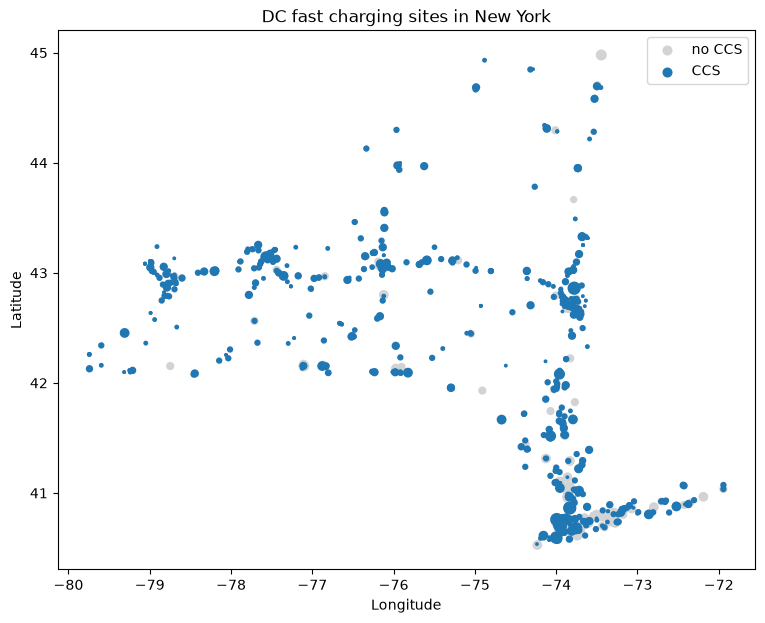

In [10]:
plt.figure(figsize=(9, 7))
plt.scatter(sites["Longitude"], sites["Latitude"], s=sites["ports"] * 3, c="lightgray", label="no CCS")
plt.scatter(sites["Longitude"][sites["ccs"]], sites["Latitude"][sites["ccs"]], s=sites["ports"][sites["ccs"]] * 3, label="CCS")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("DC fast charging sites in New York")
plt.legend()
plt.savefig("sites_map.png")
plt.show()

## 2. Distances

We need the distance between every pair of sites: a 754 x 754 table.

### 2.1 Straight-line distance x 1.2 (`D`)

The haversine formula gives the distance on the Earth's surface "as the bird flies" (3958.8 is the Earth's radius in miles). Roads are not straight, so the proposal multiplies by 1.2 (Ballou et al., 2002).

In [12]:
lat = np.radians(sites["Latitude"].values)
lon = np.radians(sites["Longitude"].values)
dlat = lat[:, None] - lat[None, :]
dlon = lon[:, None] - lon[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(lat[:, None]) * np.cos(lat[None, :]) * np.sin(dlon / 2) ** 2
straight = 2 * 3958.8 * np.arcsin(np.sqrt(a))
D = 1.2 * straight
D.shape

(754, 754)

### 2.2 Road distance from OpenStreetMap (`R`)

The OSRM "table" service gives real driving distances on the OpenStreetMap road network. We send the sites in blocks of 50 x 50 (256 requests, about 5 minutes) and wait 1 second between requests, as the free server asks.

This only runs if `road_miles.npy` does not exist yet. After the first run, the file is loaded instead.

In [14]:
if not os.path.exists("road_miles.npy"):
    n = len(sites)
    R = np.zeros((n, n))
    block = 50
    for a in range(0, n, block):
        for b in range(0, n, block):
            src = list(range(a, min(a + block, n)))
            dst = list(range(b, min(b + block, n)))
            ids = src + dst
            pts = ";".join(f"{sites['Longitude'][k]},{sites['Latitude'][k]}" for k in ids)
            s = ";".join(str(k) for k in range(len(src)))
            d = ";".join(str(k) for k in range(len(src), len(ids)))
            url = f"https://router.project-osrm.org/table/v1/driving/{pts}?sources={s}&destinations={d}&annotations=distance"
            table = np.array(requests.get(url).json()["distances"])
            R[a:a + len(src), b:b + len(dst)] = table / 1609.34
            time.sleep(1)
    R = np.minimum(R, R.T)
    np.save("road_miles.npy", R)

R = np.load("road_miles.npy")
print(R.shape, "missing:", np.isnan(R).sum())

(754, 754) missing: 0


### 2.3 How good is the 1.2 factor?

We compare road distance with straight-line distance for all pairs more than 5 miles apart. A median ratio above 1.2 means roads are longer than the standard factor assumes.

In [16]:
upper = np.triu_indices(len(sites), 1)
far = straight[upper] > 5
ratio = R[upper][far] / straight[upper][far]
print("median ratio:", np.median(ratio))
print("90% of pairs between:", np.percentile(ratio, 5), "and", np.percentile(ratio, 95))

median ratio: 1.2724227735166846
90% of pairs between: 1.099538719826694 and 1.4814800160491193


### 2.4 Distances for the CCS network

We keep only the rows and columns of `R` that belong to CCS sites. No new download is needed.

In [18]:
keep = np.where(sites["ccs"])[0]
sites_ccs = sites.iloc[keep].reset_index(drop=True)
R_ccs = R[np.ix_(keep, keep)]
print("all sites:", len(sites), "  CCS sites:", len(sites_ccs))

all sites: 754   CCS sites: 661


## 3. Building the network

**Epsilon-neighborhood graph:** each site is a node, and two sites are linked if they are at most `eps` miles apart. `eps` is the **spacing standard**: how far a driver must be able to go between chargers.

- `build_graph(dist, eps)` builds the network from any distance table (`D`, `R` or `R_ccs`).
- `connectivity(g, n)` is the function from the Pair Notebook: the size of the largest piece divided by `n`.

In [20]:
def build_graph(dist, eps):
    i, j = np.where(np.triu(dist <= eps, 1))
    return ig.Graph(n=len(dist), edges=list(zip(i, j)))

def connectivity(g, n):
    groups = g.connected_components()
    biggest = max(len(group) for group in groups)
    return biggest / n

g = build_graph(R, 50)
print("nodes:", g.vcount(), " links:", g.ecount(), " pieces:", len(g.connected_components()), " connectivity:", connectivity(g, g.vcount()))

nodes: 754  links: 36794  pieces: 1  connectivity: 1.0


## 4. Q1: when does the network split?

### 4.1 Connectivity for every standard from 5 to 100 miles

This is a **percolation curve**: as `eps` grows, more sites are linked, and at some point the pieces suddenly join together.

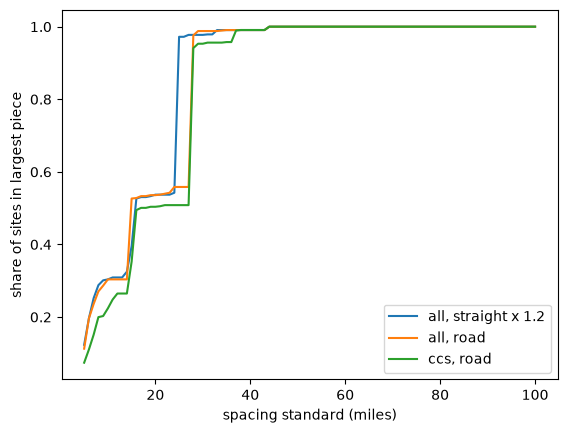

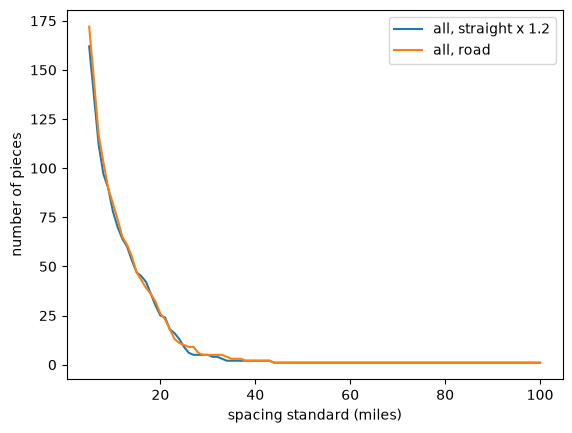

In [22]:
eps_values = np.arange(5, 101)
conn_est = []
conn_all = []
conn_ccs = []
pieces_est = []
pieces_all = []
for eps in eps_values:
    g_est = build_graph(D, eps)
    g_all = build_graph(R, eps)
    conn_est.append(connectivity(g_est, len(sites)))
    conn_all.append(connectivity(g_all, len(sites)))
    conn_ccs.append(connectivity(build_graph(R_ccs, eps), len(sites_ccs)))
    pieces_est.append(len(g_est.connected_components()))
    pieces_all.append(len(g_all.connected_components()))

plt.figure()
plt.plot(eps_values, conn_est, label="all, straight x 1.2")
plt.plot(eps_values, conn_all, label="all, road")
plt.plot(eps_values, conn_ccs, label="ccs, road")
plt.xlabel("spacing standard (miles)")
plt.ylabel("share of sites in largest piece")
plt.legend()
plt.savefig("curve_connectivity.png")
plt.show()

plt.figure()
plt.plot(eps_values, pieces_est, label="all, straight x 1.2")
plt.plot(eps_values, pieces_all, label="all, road")
plt.xlabel("spacing standard (miles)")
plt.ylabel("number of pieces")
plt.legend()
plt.savefig("curve_pieces.png")
plt.show()

### 4.2 The exact threshold: minimum spanning tree

The **minimum spanning tree (MST)** is the shortest set of links that still connects every site. Its **longest link** is exactly the smallest standard at which the whole network is one piece (proposal, Step 2(i)). We use `spanning_tree(weights=...)` as in the M03 coding notebook.

`mst_links` returns all MST links, longest first, so the top rows are the weakest links in the state.

In [24]:
def mst_links(dist, table):
    n = len(dist)
    i, j = np.triu_indices(n, 1)
    full = ig.Graph(n=n, edges=list(zip(i, j)))
    full.es["weight"] = dist[i, j]
    mst = full.spanning_tree(weights=full.es["weight"])
    rows = []
    for e in mst.es:
        rows.append([e["weight"], table["city"][e.source], table["city"][e.target]])
    links = pd.DataFrame(rows, columns=["miles", "from", "to"])
    return links.sort_values("miles", ascending=False).reset_index(drop=True)

links_est = mst_links(D, sites)
links_all = mst_links(R, sites)
links_ccs = mst_links(R_ccs, sites_ccs)

print("threshold, all, straight x 1.2:", links_est["miles"][0])
print("threshold, all, road:", links_all["miles"][0])
print("threshold, ccs, road:", links_ccs["miles"][0])

threshold, all, straight x 1.2: 43.11515633669068
threshold, all, road: 43.523556240446396
threshold, ccs, road: 43.523556240446396


The 10 weakest links in each version:

In [26]:
pd.concat([links_est.head(10), links_all.head(10), links_ccs.head(10)], axis=1, keys=["all, straight x 1.2", "all, road", "ccs, road"])

all, straight x 1.2                                 all, road  \
                miles           from              to      miles   
0           43.115156   Saranac Lake          Malone  43.523556   
1           33.850982         Malone         Massena  37.168218   
2           32.089664        Pulaski       Watertown  34.640349   
3           30.290755    Chestertown     Indian Lake  33.240024   
4           26.326177     Monticello          Roscoe  28.322853   
5           25.878728      Watertown    Cape Vincent  27.997254   
6           25.863534         Roscoe        Arkville  27.115650   
7           25.002256      Watertown  Alexandria Bay  27.083836   
8           24.834604          Lewis            Peru  25.562032   
9           24.756452  Whitney Point        Cortland  24.898903   

                                ccs, road                               
            from            to      miles           from            to  
0   Saranac Lake        Malone  43.523556   Saranac Lake        Malone  
1         Malone       Massena  37.168218         Malone       Massena  
2       Arkville  TANNERSVILLE  37.040464    Warrensburg   Indian Lake  
3    Chestertown   Indian Lake  36.027502    Warrensburg  North Hudson  
4        Pulaski     Watertown  34.640349       Arkville  TANNERSVILLE  
5    Fultonville  Little Falls  30.863895        Hancock         Afton  
6     Monticello        Roscoe  28.322853        Pulaski     Watertown  
7  Elizabethtown   Lake Placid  27.997254    Fultonville  Little Falls  
8         Roscoe       Hancock  27.083836  Elizabethtown   Lake Placid  
9     Binghamton         Afton  24.898903     Binghamton         Afton

### 4.3 What are the pieces?

Just below the big jump in the curve (24 miles), we colour each piece differently to see which regions they are.

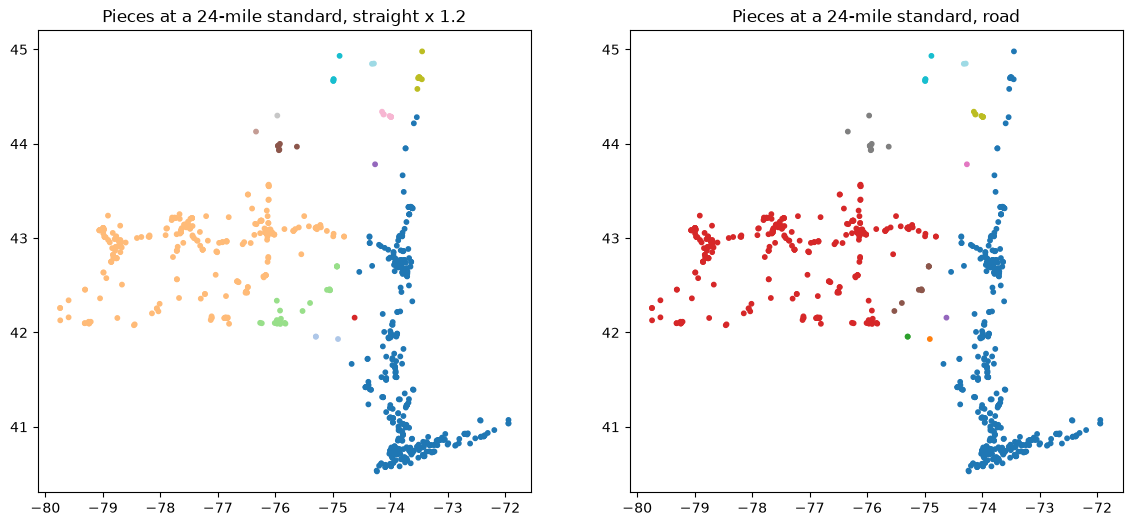

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, dist, title in [(axes[0], D, "straight x 1.2"), (axes[1], R, "road")]:
    membership = build_graph(dist, 24).connected_components().membership
    ax.scatter(sites["Longitude"], sites["Latitude"], c=membership, cmap="tab20", s=10)
    ax.set_title(f"Pieces at a 24-mile standard, {title}")
plt.savefig("pieces_24.png")
plt.show()

## 5. Q2: which stations hold the network together?

### 5.1 Single points of failure for every standard

An **articulation point** is a site whose loss alone splits its piece of the network: a single point of failure. `articulation_points()` is built into igraph. We count them for every standard from 20 to 60 miles, for both versions.

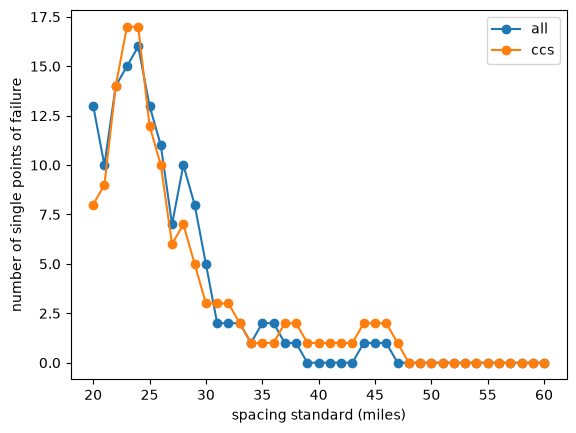

,miles,pieces_all,cut_all,cities_all,pieces_ccs,cut_ccs,cities_ccs
0,20,26,13,"[East Hampton, Stone Ridge, Olean, Sherman, Painted Post, Westfield, Bath, Watkins Glen, North Collins, Schoharie, Pembroke, Oneida, Warrensburg]",26,8,"[Stone Ridge, Sherman, Westfield, Watkins Glen, North Collins, Schoharie, Pembroke, Oneida]"
1,21,23,10,"[East Hampton, Stone Ridge, Sherman, Angelica, Westfield, South Dayton, Hornell, North Collins, Schoharie, Warrensburg]",22,9,"[Stone Ridge, Sherman, Angelica, Westfield, South Dayton, Hornell, Watkins Glen, North Collins, Schoharie]"
2,22,18,14,"[Stone Ridge, Sherman, Angelica, Sidney, Westfield, Hornell, Oneonta, Oneonta, Schoharie, Geneseo, Williamson, Warrensburg, Chestertown, North Hudson]",17,14,"[Bridgehampton, Montauk, Stone Ridge, Sherman, Angelica, Sidney, Westfield, Hornell, Oneonta, Oneonta, Dansville, Schoharie, Geneseo, Williamson]"
3,23,13,15,"[Stone Ridge, Olean, Sherman, Friendship, Angelica, Sidney, Whitney Point, Westfield, Hornell, Oneonta, Schoharie, Geneseo, Warrensburg, Chestertown, Elizabethtown]",13,17,"[Bridgehampton, Montauk, Stone Ridge, Olean, Sherman, Friendship, Angelica, Sidney, Whitney Point, Westfield, Hornell, Oneonta, Dansville, Schoharie, Geneseo, Williamson, Elizabethtown]"
4,24,11,16,"[Sherman, Friendship, Angelica, Sidney, Whitney Point, Westfield, Hornell, Schoharie, Geneseo, Warrensburg, Chestertown, Watertown, Elizabethtown, Lewis, Alexandria Bay, Peru]",11,17,"[Bridgehampton, Montauk, Sherman, Friendship, Angelica, Sidney, Whitney Point, Westfield, Hornell, Dansville, Schoharie, Geneseo, Watertown, Elizabethtown, Lewis, Alexandria Bay, Peru]"
5,25,10,13,"[Binghamton, Friendship, Afton, Sidney, Whitney Point, Westfield, Hornell, Schoharie, Warrensburg, Chestertown, Elizabethtown, Lewis, Peru]",10,12,"[Bridgehampton, Binghamton, Friendship, Afton, Sidney, Whitney Point, Westfield, Hornell, Schoharie, Elizabethtown, Lewis, Peru]"
6,26,9,11,"[Friendship, Afton, Sidney, Whitney Point, Hornell, Schoharie, Warrensburg, Chestertown, Elizabethtown, Lewis, Peru]",10,10,"[Binghamton, Friendship, Afton, Sidney, Whitney Point, Hornell, Schoharie, Elizabethtown, Lewis, Peru]"
7,27,9,7,"[Friendship, Hornell, Schoharie, Chestertown, Elizabethtown, Lewis, Peru]",10,6,"[Friendship, Hornell, Schoharie, Elizabethtown, Lewis, Peru]"
8,28,6,10,"[Monticello, Roscoe, Hornell, Schoharie, Fultonville, Little Falls, Chestertown, Elizabethtown, Lewis, Peru]",8,7,"[Hornell, Schoharie, Fultonville, Little Falls, Elizabethtown, Lewis, Peru]"
9,29,5,8,"[Monticello, Roscoe, Hornell, Schoharie, Pulaski, Chestertown, Elizabethtown, Peru]",7,5,"[Hornell, Schoharie, Pulaski, Elizabethtown, Peru]"


In [30]:
rows = []
for eps in range(20, 61):
    g_all = build_graph(R, eps)
    g_ccs = build_graph(R_ccs, eps)
    cut_all = g_all.articulation_points()
    cut_ccs = g_ccs.articulation_points()
    rows.append([eps, len(g_all.connected_components()), len(cut_all), [sites["city"][v] for v in cut_all],
                 len(g_ccs.connected_components()), len(cut_ccs), [sites_ccs["city"][v] for v in cut_ccs]])

ap = pd.DataFrame(rows, columns=["miles", "pieces_all", "cut_all", "cities_all", "pieces_ccs", "cut_ccs", "cities_ccs"])

plt.figure()
plt.plot(ap["miles"], ap["cut_all"], marker="o", label="all")
plt.plot(ap["miles"], ap["cut_ccs"], marker="o", label="ccs")
plt.xlabel("spacing standard (miles)")
plt.ylabel("number of single points of failure")
plt.legend()
plt.savefig("ap_count.png")
plt.show()

pd.set_option("display.max_colwidth", None)
ap

### 5.2 How much damage does each one do?

For each single point of failure, `critical_sites`:
1. finds the piece of the network it belongs to,
2. closes it on a copy of the network (removes all its links, as in walkthrough step 7),
3. counts how many sites of that piece are cut off from the rest (`sites_cut_off`).

It also reports the site's **degree** (number of neighbours) and **ports**, to answer "are the critical stations big or small?", and its **operator** (`EV Network`).

In [32]:
def critical_sites(g, table):
    membership = g.connected_components().membership
    rows = []
    for v in g.articulation_points():
        piece = [u for u in range(g.vcount()) if membership[u] == membership[v] and u != v]
        h = g.copy()
        h.delete_edges(h.incident(v))
        new_membership = h.connected_components().membership
        sizes = pd.Series([new_membership[u] for u in piece]).value_counts()
        lost = len(piece) - sizes.max()
        rows.append([v, table["name"][v], table["city"][v], table["network"][v], g.degree(v), table["ports"][v], lost])
    crit = pd.DataFrame(rows, columns=["id", "name", "city", "operator", "degree", "ports", "sites_cut_off"])
    return crit.sort_values("sites_cut_off", ascending=False)

At a 30-mile standard, all sites:

In [34]:
critical_sites(build_graph(R, 30), sites)

,id,name,city,operator,degree,ports,sites_cut_off
2,712,"Chestertown, NY - Tesla Supercharger",Chestertown,Tesla,8,6,24
4,735,"Peru, NY - Tesla Supercharger",Peru,Tesla,12,8,11
3,724,Egglefield Bros,Elizabethtown,FORD_CHARGE,9,2,8
0,267,"Monticello, NY - Tesla Supercharger",Monticello,Tesla,9,12,3
1,279,"Roscoe, NY - Tesla Supercharger",Roscoe,Tesla,3,8,2


At a 30-mile standard, CCS sites only:

In [36]:
critical_sites(build_graph(R_ccs, 30), sites_ccs)

,id,name,city,operator,degree,ports,sites_cut_off
2,645,"Peru, NY - Tesla Supercharger",Peru,Tesla,11,8,9
0,290,Simmons Rockwell Ford Hornell NY,Hornell,RED_E,8,4,7
1,635,Egglefield Bros,Elizabethtown,FORD_CHARGE,8,2,7


At a 45-mile standard, CCS sites only. Without the Tesla-only Chestertown site, Warrensburg becomes the only link to the Adirondacks and the North Country.

In [38]:
critical_sites(build_graph(R_ccs, 45), sites_ccs)

,id,name,city,operator,degree,ports,sites_cut_off
0,620,Warren Ford,Warrensburg,FORD_CHARGE,24,2,28
1,644,Upstate Auto,Saranac Lake,VIALYNK,10,2,6


### 5.3 Are the critical stations big or small?

We compare the median degree of all sites with the median degree of the critical sites.

In [40]:
summary = []
for eps in [25, 30, 35, 40, 45, 50]:
    for name, dist, table in [("all", R, sites), ("ccs", R_ccs, sites_ccs)]:
        g = build_graph(dist, eps)
        crit = critical_sites(g, table)
        summary.append([eps, name, len(crit), np.median(g.degree()), crit["degree"].median()])

pd.DataFrame(summary, columns=["miles", "network", "critical_sites", "median_degree_all", "median_degree_critical"])

,miles,network,critical_sites,median_degree_all,median_degree_critical
0,25,all,13,42.0,6.0
1,25,ccs,12,39.0,7.0
2,30,all,5,50.0,9.0
3,30,ccs,3,47.0,8.0
4,35,all,2,58.0,23.5
5,35,ccs,1,53.0,27.0
6,40,all,0,66.0,NaN
7,40,ccs,1,62.0,23.0
8,45,all,1,73.0,11.0
9,45,ccs,2,68.0,17.0


### 5.4 Map of the single points of failure

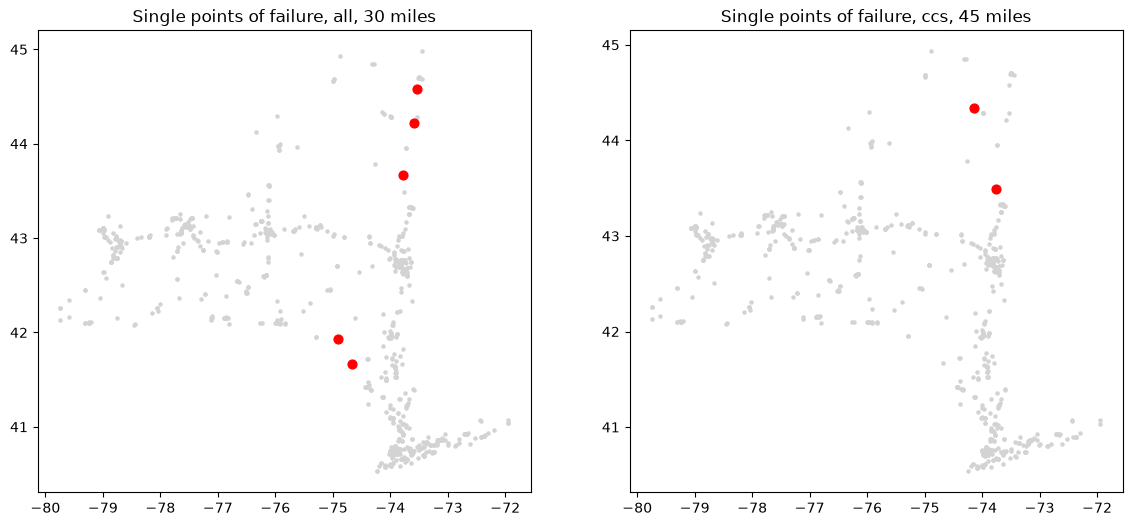

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, dist, table, eps, name in [(axes[0], R, sites, 30, "all"), (axes[1], R_ccs, sites_ccs, 45, "ccs")]:
    crit = critical_sites(build_graph(dist, eps), table)
    ax.scatter(table["Longitude"], table["Latitude"], s=5, c="lightgray")
    ax.scatter(table["Longitude"][crit["id"]], table["Latitude"][crit["id"]], s=40, c="red")
    ax.set_title(f"Single points of failure, {name}, {eps} miles")
plt.savefig("critical_map.png")
plt.show()

## 6. Q2: random failure of many stations

Following the professor's feedback, several stations can fail at the same time (storms, power cuts, broken equipment). Each site fails independently with probability `p`. For each `p` we repeat 100 times and take the average connectivity.

- Failed sites still count in the total `n`, as in the Pair Notebook, so the best possible connectivity is `1 - p` (dashed line).
- **R** is the average height of the curve. Over `p` from 0 to 0.6 it is at most about 0.7.
- `rng = np.random.default_rng(42)` makes the result the same on every run.

### 6.1 One standard: 50 miles, all sites

In [44]:
def random_failure(dist, eps, p_values, trials, rng):
    g = build_graph(dist, eps)
    n = g.vcount()
    mean_conn = []
    for p in p_values:
        results = []
        for t in range(trials):
            failed = np.where(rng.random(n) < p)[0]
            h = g.copy()
            h.delete_vertices(failed)
            results.append(connectivity(h, n))
        mean_conn.append(np.mean(results))
    return np.array(mean_conn)

rng = np.random.default_rng(42)
p_values = np.arange(0, 0.61, 0.05)
trials = 100

curve_50 = random_failure(R, 50, p_values, trials, rng)
print("R:", curve_50.mean())
pd.DataFrame({"p": p_values, "connectivity": curve_50})

R: 0.6976106916955724


,p,connectivity
0,0.00,1.000000
1,0.05,0.949987
2,0.10,0.900836
3,0.15,0.849549
4,0.20,0.798302
5,0.25,0.748037
6,0.30,0.698130
7,0.35,0.648740
8,0.40,0.598859
9,0.45,0.547812


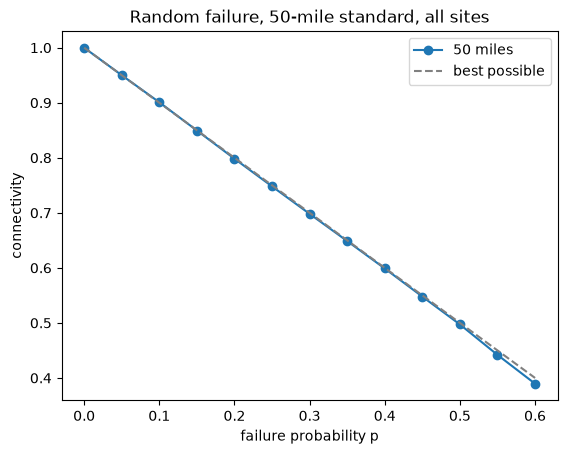

In [45]:
plt.figure()
plt.plot(p_values, curve_50, marker="o", label="50 miles")
plt.plot(p_values, 1 - p_values, linestyle="--", c="gray", label="best possible")
plt.xlabel("failure probability p")
plt.ylabel("connectivity")
plt.title("Random failure, 50-mile standard, all sites")
plt.legend()
plt.savefig("random_failure_50.png")
plt.show()

### 6.2 Several standards, both versions

The last column is the share of the **surviving** sites that are still in the largest piece when 60% of sites have failed. 1.0 means the network did not split at all.

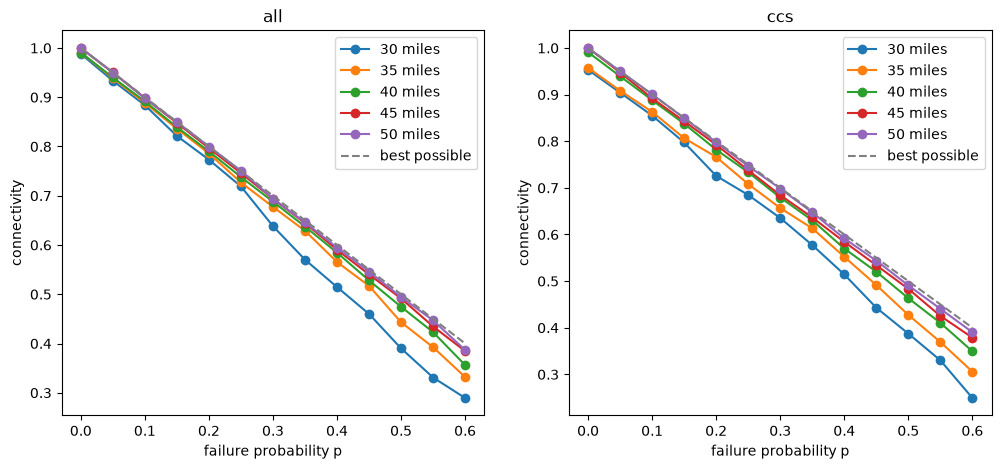

,network,miles,R,survivors_connected_at_p_0.6
0,all,30,0.639416,0.723375
1,all,35,0.670976,0.829907
2,all,40,0.683211,0.890550
3,all,45,0.693721,0.961572
4,all,50,0.696715,0.966844
5,ccs,30,0.619766,0.623336
6,ccs,35,0.648166,0.764486
7,ccs,40,0.676475,0.873563
8,ccs,45,0.687655,0.946823
9,ccs,50,0.696013,0.975756


In [47]:
summary = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name, dist in [(axes[0], "all", R), (axes[1], "ccs", R_ccs)]:
    for eps in [30, 35, 40, 45, 50]:
        curve = random_failure(dist, eps, p_values, trials, rng)
        ax.plot(p_values, curve, marker="o", label=f"{eps} miles")
        summary.append([name, eps, curve.mean(), curve[-1] / (1 - p_values[-1])])
    ax.plot(p_values, 1 - p_values, linestyle="--", c="gray", label="best possible")
    ax.set_title(name)
    ax.set_xlabel("failure probability p")
    ax.set_ylabel("connectivity")
    ax.legend()
plt.savefig("random_failure.png")
plt.show()

pd.DataFrame(summary, columns=["network", "miles", "R", "survivors_connected_at_p_0.6"])

## 7. Q2: targeted attack

In a **targeted attack**, the most important sites are removed first, one after another (M03 lecture note). We use the **adaptive** version from the lecture: after every removal, the scores are recomputed on what is left.

Two ways to decide "most important":
- **degree**: the site with the most neighbours. This is the attack used in the M03 coding notebook.
- **betweenness**: the site that lies on the most shortest paths between other sites, i.e. a **bridge** between regions (`g.betweenness()`, covered in Module 6).

`targeted_attack(g, steps, criterion)` removes `steps` sites and records connectivity after each removal. Because igraph renumbers nodes after a deletion, each node keeps its original site number in `h.vs["site"]`, so we know which site was removed.

In [49]:
def targeted_attack(g, steps, criterion):
    h = g.copy()
    h.vs["site"] = list(range(h.vcount()))
    n = g.vcount()
    curve = [connectivity(h, n)]
    removed = []
    for k in range(steps):
        if criterion == "degree":
            score = h.degree()
        else:
            score = h.betweenness()
        v = int(np.argmax(score))
        removed.append(h.vs[v]["site"])
        h.delete_vertices([v])
        curve.append(connectivity(h, n))
    return np.array(curve), removed

### 7.1 Random failure vs targeted attack

We remove up to 60% of the sites, as in Section 6, at a 50-mile and a 30-mile standard. The x-axis is the share of sites removed. For random failure this is `p`.

This takes about 15 seconds.

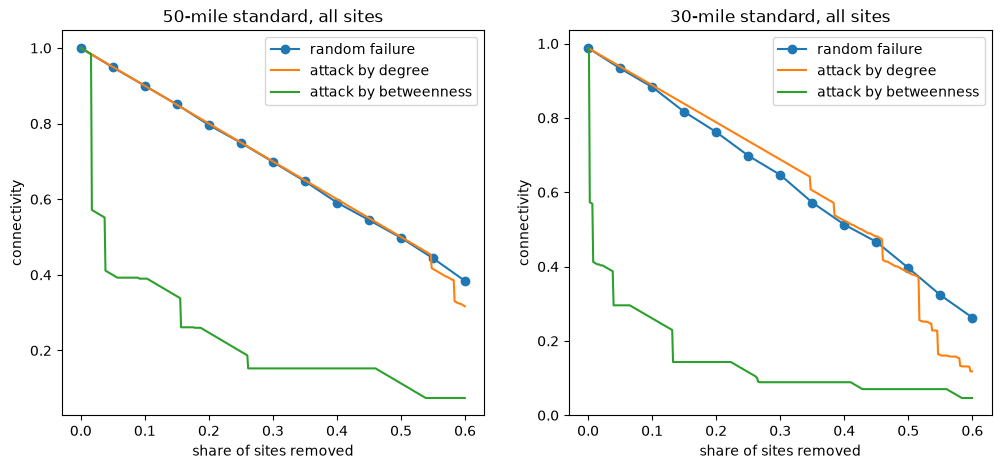

,miles,R_random,R_degree,R_betweenness
0,50,0.696345,0.695809,0.237105
1,30,0.635552,0.634043,0.145663


In [51]:
steps = int(0.6 * len(sites))
f_values = np.arange(steps + 1) / len(sites)

attack = {}
summary = []
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, eps in [(axes[0], 50), (axes[1], 30)]:
    g = build_graph(R, eps)
    curve_random = random_failure(R, eps, p_values, trials, rng)
    curve_degree, removed_degree = targeted_attack(g, steps, "degree")
    curve_betw, removed_betw = targeted_attack(g, steps, "betweenness")
    attack[eps] = [removed_degree, removed_betw]
    ax.plot(p_values, curve_random, marker="o", label="random failure")
    ax.plot(f_values, curve_degree, label="attack by degree")
    ax.plot(f_values, curve_betw, label="attack by betweenness")
    ax.set_title(f"{eps}-mile standard, all sites")
    ax.set_xlabel("share of sites removed")
    ax.set_ylabel("connectivity")
    ax.legend()
    summary.append([eps, curve_random.mean(), curve_degree.mean(), curve_betw.mean()])
plt.savefig("targeted_attack.png")
plt.show()

pd.DataFrame(summary, columns=["miles", "R_random", "R_degree", "R_betweenness"])

### 7.2 Which sites does each attack remove first?

The first 15 sites removed at a 50-mile standard.

In [53]:
removed_degree, removed_betw = attack[50]
pd.DataFrame({
    "attack by degree": [sites["city"][v] for v in removed_degree[:15]],
    "attack by betweenness": [sites["city"][v] for v in removed_betw[:15]],
})

,attack by degree,attack by betweenness
0,Bronx,Schoharie
1,Bronx,Arkville
2,The Bronx,Roscoe
3,The Bronx,Herkimer
4,North New Hyde Park,Herkimer
5,Jackson Heights,Little Falls
6,Queens,Little Falls
7,Roslyn Heights,Frankfort
8,Great Neck,Richmondville
9,Bronx,Johnstown


### 7.3 How few sites does it take?

Connectivity after removing the first few sites by betweenness, at 50 miles.

In [55]:
g = build_graph(R, 50)
curve_betw, removed_betw = targeted_attack(g, 40, "betweenness")
pd.DataFrame({"sites_removed": range(41), "connectivity": curve_betw}).iloc[[0, 5, 10, 15, 20, 25, 30, 35, 40]]

,sites_removed,connectivity
0,0,1.000000
5,5,0.993369
10,10,0.986737
15,15,0.568966
20,20,0.562334
25,25,0.555703
30,30,0.409814
35,35,0.403183
40,40,0.396552


**Note.** Connectivity is dominated by the dense New York City and Long Island area (about a third of all sites). A region like the North Country (about 6% of sites) can be cut off with little change in this number. The next step is a **coverage** measure based on cities and population, as the professor suggested.

## 8. Cities and population

To measure coverage we need the cities of New York State. We use two Census 2020 files:

- `2020_gaz_place_36.txt` (Census Gazetteer) gives the center point (INTPTLAT, INTPTLONG) of every place in the state.
- `DECENNIALPL2020.P1-Data.csv` gives the 2020 population of every place (column P1_001N).

We join the two files on the place code (GEOID). There are 1293 places, many of them tiny hamlets, so we keep only the places with at least 5000 people. That leaves 362 places, which hold about 92% of the state's population. Each city is represented by its center point.

This step only runs if `ny_places.csv` does not exist yet. After the first run, the file is loaded instead, so the two Census files are needed only once.

In [58]:
if not os.path.exists("ny_places.csv"):
    gaz = pd.read_csv("2020_gaz_place_36.txt", sep="\t")
    gaz.columns = gaz.columns.str.strip()

    pop = pd.read_csv("DECENNIALPL2020.P1-Data.csv", usecols=["GEO_ID", "P1_001N"])
    pop = pop.iloc[1:]
    pop["GEOID"] = pop["GEO_ID"].str[-7:].astype(int)
    pop["pop"] = pop["P1_001N"].astype(int)

    places = gaz.merge(pop, on="GEOID")
    places = places[["GEOID", "NAME", "pop", "INTPTLAT", "INTPTLONG"]]
    places.columns = ["geoid", "name", "pop", "lat", "lon"]
    places.to_csv("ny_places.csv", index=False)

places = pd.read_csv("ny_places.csv")
print("places:", len(places))
places.head()

places: 1293


,geoid,name,pop,lat,lon
0,3600155,Accord CDP,573,41.801491,-74.230258
1,3600199,Adams village,1633,43.810218,-76.022978
2,3600232,Adams Center CDP,1492,43.869989,-75.988663
3,3600276,Addison village,1561,42.106321,-77.231990
4,3600342,Afton village,794,42.229199,-75.524750


## 9. Coverage: can people in one city reach another city?

Connectivity counts charging sites, so it is dominated by the dense New York City area. As the professor suggested, we now measure the network from the point of view of **people and cities**.

### 9.1 Distance from each city to the chargers

We load the city file and keep places with at least 5000 people (362 places). For each city center and each charging site we compute the haversine distance × 1.2, the same rule as in section 2. The result is a 362 × 754 matrix `C`.

For this city-to-charger step we use straight-line × 1.2, not road distance. It is a short "last mile" trip (half the cities have a charger within 2 miles), so the two are very close. Between sites we keep using road distances `R`.

In [60]:
places = pd.read_csv("ny_places.csv")
places = places[places["pop"] >= 5000].reset_index(drop=True)

clat = np.radians(places["lat"].values)
clon = np.radians(places["lon"].values)
slat = np.radians(sites["Latitude"].values)
slon = np.radians(sites["Longitude"].values)
dlat = clat[:, None] - slat[None, :]
dlon = clon[:, None] - slon[None, :]
a = np.sin(dlat / 2) ** 2 + np.cos(clat[:, None]) * np.cos(slat[None, :]) * np.sin(dlon / 2) ** 2
C = 1.2 * 2 * 3958.8 * np.arcsin(np.sqrt(a))

places["nearest"] = C.min(axis=1)
print(C.shape)
places.sort_values("nearest", ascending=False).head(10)

(362, 754)


,geoid,name,pop,lat,lon,nearest
241,3654485,Ogdensburg city,10064,44.709180,-75.463271,28.097299
237,3653979,Norwich city,7051,42.533322,-75.522758,19.916723
3,3601033,Albion village,5637,43.246024,-78.190200,18.025488
189,3646415,Medina village,6047,43.219742,-78.387874,17.581850
263,3659388,Port Jervis city,8775,41.378021,-74.690802,16.530677
35,3612331,Canton village,7155,44.599995,-75.166584,11.764226
116,3631786,Hamlin CDP,5177,43.302295,-77.921682,10.378813
94,3626759,Fort Drum CDP,15896,44.044709,-75.787763,8.732484
30,3608466,Brockport village,7104,43.213297,-77.940824,8.579446
61,3621589,East Aurora village,5998,42.766837,-78.617042,8.433604


### 9.2 Coverage metric

For a given standard `eps`:

1. A city is **attached** to a charging site if the site is within `eps` miles of the city center. A city can be attached to several sites.
2. Two cities A and B are **connected** if some site attached to A and some site attached to B are in the same piece of the network.
3. **Coverage (unweighted)** = share of city pairs that are connected. Every city counts the same.
4. **Coverage (weighted)** = the same share, but each pair counts by pop_A × pop_B. Pairs of big cities matter more, because more trips happen between them.

In the code, `M` is a table with one row per city and one column per piece of the network. A 1 means the city touches that piece. Two cities share a piece exactly when `M @ M.T` is above 0 for that pair.

In [62]:
def coverage(g, C, eps, pop):
    membership = np.array(g.connected_components().membership)
    M = np.zeros((len(C), membership.max() + 1))
    i, j = np.where(C <= eps)
    M[i, membership[j]] = 1
    reach = (M @ M.T) > 0
    w = np.outer(pop, pop)
    np.fill_diagonal(reach, False)
    np.fill_diagonal(w, 0)
    n = len(pop)
    return reach.sum() / (n * (n - 1)), (w * reach).sum() / w.sum()

### 9.3 Coverage vs the spacing standard

We compare connectivity (section 4) with unweighted and weighted coverage for every standard from 1 to 80 miles, using road distances between sites.

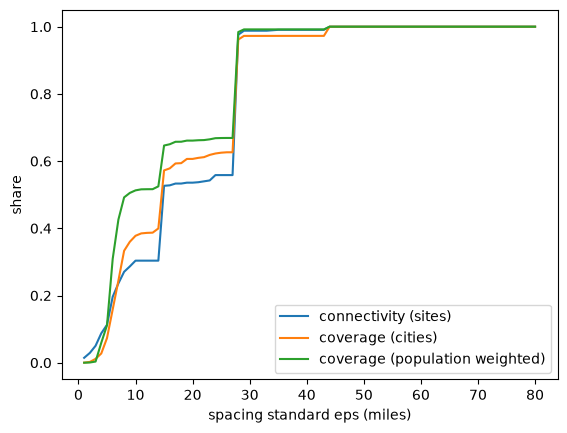

,eps,connectivity,coverage,coverage_weighted
9,10,0.303714,0.377741,0.512913
19,20,0.535809,0.606510,0.661003
23,24,0.558355,0.622626,0.668198
29,30,0.988064,0.972621,0.991970
39,40,0.990716,0.972682,0.991972
49,50,1.000000,1.000000,1.000000


In [64]:
pop = places["pop"].values.astype(float)
eps_list = range(1, 81)
rows = []
for eps in eps_list:
    g = build_graph(R, eps)
    u, w = coverage(g, C, eps, pop)
    rows.append([eps, connectivity(g, len(R)), u, w])
cov = pd.DataFrame(rows, columns=["eps", "connectivity", "coverage", "coverage_weighted"])

plt.figure()
plt.plot(cov["eps"], cov["connectivity"], label="connectivity (sites)")
plt.plot(cov["eps"], cov["coverage"], label="coverage (cities)")
plt.plot(cov["eps"], cov["coverage_weighted"], label="coverage (population weighted)")
plt.xlabel("spacing standard eps (miles)")
plt.ylabel("share")
plt.legend()
plt.savefig("coverage_curve.png")
plt.show()

cov[cov["eps"].isin([10, 20, 24, 30, 40, 50])]

## 10. Robustness measured by coverage

In sections 5–7 we measured damage by connectivity (how many sites are cut off). Now we measure it by coverage: how many city pairs, and how many people, lose their connection.

`coverage_after` removes the failed sites, rebuilds the network from the remaining sites, and computes coverage. A removed site can no longer link to other sites, and cities can no longer use it.

### 10.1 Failure of a single site

We remove each of the 754 sites alone and record how much coverage drops. This takes about 20 seconds per standard.

In [66]:
def coverage_after(dist, C, eps, pop, failed):
    keep = np.setdiff1d(np.arange(len(dist)), failed)
    g = build_graph(dist[np.ix_(keep, keep)], eps)
    return coverage(g, C[:, keep], eps, pop)

for eps in [30, 50]:
    base_u, base_w = coverage(build_graph(R, eps), C, eps, pop)
    rows = []
    for v in range(len(sites)):
        u, w = coverage_after(R, C, eps, pop, [v])
        rows.append([sites["name"][v], sites["city"][v], base_u - u, base_w - w])
    loss = pd.DataFrame(rows, columns=["name", "city", "coverage_lost", "weighted_lost"])
    print(eps, "miles:", (loss["coverage_lost"] > 0).sum(), "sites reduce coverage")
    print(loss[loss["coverage_lost"] > 0])

30 miles: 2 sites reduce coverage
                                     name         city  coverage_lost  \
712  Chestertown, NY - Tesla Supercharger  Chestertown       0.005448   
735         Peru, NY - Tesla Supercharger         Peru       0.005448   

     weighted_lost  
712       0.003864  
735       0.003864  
50 miles: 0 sites reduce coverage
Empty DataFrame
Columns: [name, city, coverage_lost, weighted_lost]
Index: []


### 10.2 Random failure

Same as section 6: each site fails with probability `p`, 100 trials per `p`, but we record coverage. Unlike connectivity, the best possible coverage is 1 and does not shrink with `p`, because a city only needs one working charger nearby.

In [68]:
def random_failure_coverage(dist, C, eps, pop, p_values, trials, rng):
    n = len(dist)
    mean_u = []
    mean_w = []
    for p in p_values:
        us = []
        ws = []
        for t in range(trials):
            failed = np.where(rng.random(n) < p)[0]
            u, w = coverage_after(dist, C, eps, pop, failed)
            us.append(u)
            ws.append(w)
        mean_u.append(np.mean(us))
        mean_w.append(np.mean(ws))
    return np.array(mean_u), np.array(mean_w)

### 10.3 Random failure vs targeted attack, by coverage

We take the removal order from section 7 (`attack[eps]`), remove the first k sites in that order, and compute coverage for every k. The top row is unweighted coverage; the bottom row is population-weighted. This takes about a minute.

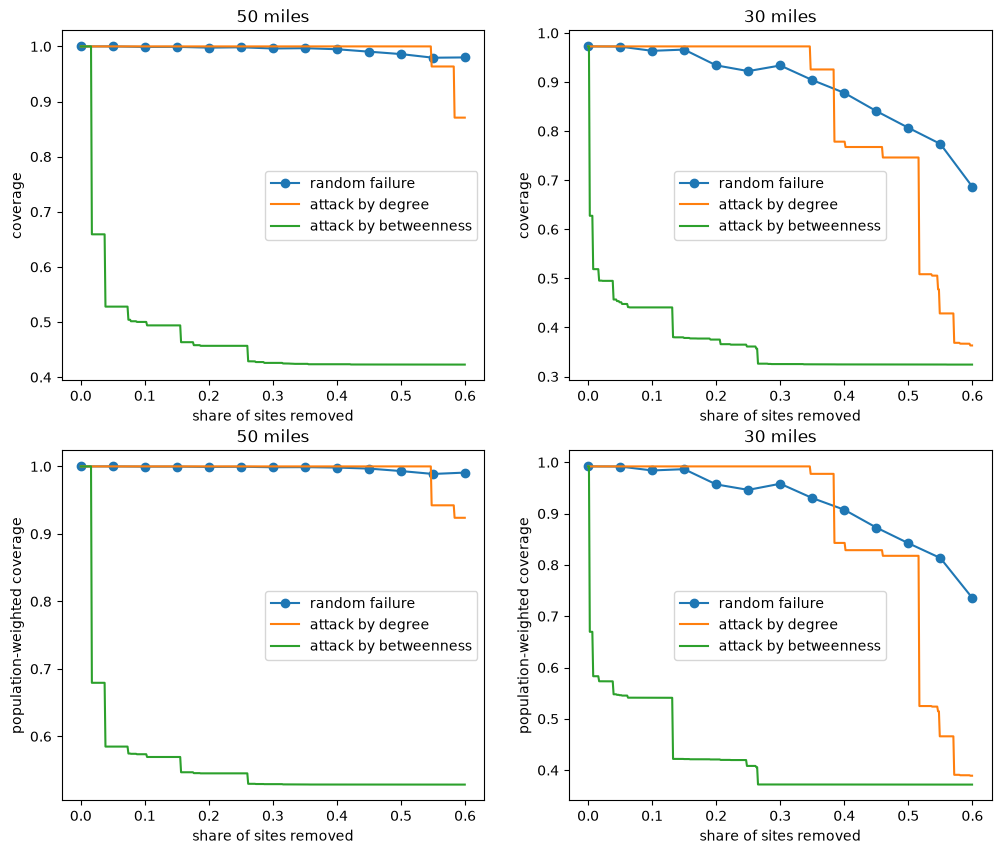

,miles,R_random,R_degree,R_betweenness,Rw_random,Rw_degree,Rw_betweenness
0,50,0.993713,0.994121,0.470771,0.997202,0.994378,0.559563
1,30,0.888825,0.848147,0.368373,0.916713,0.880624,0.424827


In [70]:
def attack_coverage(dist, C, eps, pop, removed):
    us = []
    ws = []
    for k in range(len(removed) + 1):
        u, w = coverage_after(dist, C, eps, pop, removed[:k])
        us.append(u)
        ws.append(w)
    return np.array(us), np.array(ws)

summary = []
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for col, eps in [(0, 50), (1, 30)]:
    removed_degree, removed_betw = attack[eps]
    ru, rw = random_failure_coverage(R, C, eps, pop, p_values, trials, rng)
    du, dw = attack_coverage(R, C, eps, pop, removed_degree)
    bu, bw = attack_coverage(R, C, eps, pop, removed_betw)
    for row, r, d, b in [(0, ru, du, bu), (1, rw, dw, bw)]:
        ax = axes[row, col]
        ax.plot(p_values, r, marker="o", label="random failure")
        ax.plot(f_values, d, label="attack by degree")
        ax.plot(f_values, b, label="attack by betweenness")
        ax.set_title(f"{eps} miles")
        ax.set_xlabel("share of sites removed")
        ax.legend()
    axes[0, col].set_ylabel("coverage")
    axes[1, col].set_ylabel("population-weighted coverage")
    summary.append([eps, ru.mean(), du.mean(), bu.mean(), rw.mean(), dw.mean(), bw.mean()])
plt.savefig("coverage_attack.png")
plt.show()

pd.DataFrame(summary, columns=["miles", "R_random", "R_degree", "R_betweenness",
                               "Rw_random", "Rw_degree", "Rw_betweenness"])

## 11. Q3: how many new stations does each standard need?

### 11.1 Candidate locations

As in the proposal (Step 3), new fast chargers can only be placed at locations that already have public **Level 1 or Level 2** charging: they already have a grid connection and a host business.

From the full AFDC list for New York (`all_station.csv`, all charger types) we keep stations that are open, public, have Level 1 or Level 2 ports and **no** DC fast ports, and merge stations at the same location. This gives 4756 candidate locations, saved once as `candidates.csv`. The step only runs if that file does not exist yet.

In [72]:
if not os.path.exists("candidates.csv"):
    stations = pd.read_csv("all_station.csv", low_memory=False)

    stations["EV Level1 EVSE Num"] = stations["EV Level1 EVSE Num"].fillna(0)
    stations["EV Level2 EVSE Num"] = stations["EV Level2 EVSE Num"].fillna(0)
    stations["EV DC Fast Count"] = stations["EV DC Fast Count"].fillna(0)

    slow = stations[((stations["EV Level1 EVSE Num"] > 0) | (stations["EV Level2 EVSE Num"] > 0)) & (stations["EV DC Fast Count"] == 0)]
    slow = slow[(slow["Status Code"] == "E") & (slow["Access Code"] == "public")]

    cand = slow.groupby(["Latitude", "Longitude"], as_index=False).agg(
        name=("Station Name", "first"),
        city=("City", "first"),
        l1=("EV Level1 EVSE Num", "sum"),
        l2=("EV Level2 EVSE Num", "sum"),
    )
    cand.columns = ["lat", "lon", "name", "city", "l1", "l2"]
    cand.to_csv("candidates.csv", index=False)

cand = pd.read_csv("candidates.csv")
print("candidate locations:", len(cand))
cand.head()

candidate locations: 4756


,lat,lon,name,city,l1,l2
0,40.513465,-74.251418,Angelina's Ristorante - Tesla Destination,Staten Island,0.0,3.0
1,40.578866,-73.972561,532 Neptune Avenue,Brooklyn,0.0,6.0
2,40.578973,-73.975113,626 Sheepshead Bay Rd - Parking,Brooklyn,0.0,5.0
3,40.579780,-73.974390,532 Neptune Avenue,Brooklyn,0.0,8.0
4,40.581432,-74.097694,Nissan of Staten Island,Staten Island,0.0,1.0


### 11.2 Adding stations one at a time (greedy)

For a given standard `eps`:

1. Try every candidate location. Add it to the network and compute coverage.
2. Keep the candidate that raises coverage the most.
3. Repeat until coverage is 1, i.e. every pair of cities is connected.

To save time, a candidate is skipped when it cannot change coverage: it touches only one piece of the network and every city near it is already attached to that piece.

Sometimes a gap is longer than one standard, so no single new station raises coverage (two or more are needed in a row). In that case we take one step across the gap: among candidates within `eps` of the main piece, we add the one closest to the nearest cut-off piece, but only if it is closer than the main piece already is. If no candidate gets closer, the gap cannot be closed with the existing candidate locations and we stop.

Distances that involve a new station use straight-line × 1.2. Between existing sites we keep road distances `R`.

Because the method is greedy, the counts are an upper bound on what is needed.

In [74]:
def miles(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = np.radians(lat1), np.radians(lon1), np.radians(lat2), np.radians(lon2)
    dlat = lat1[:, None] - lat2[None, :]
    dlon = lon1[:, None] - lon2[None, :]
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1[:, None]) * np.cos(lat2[None, :]) * np.sin(dlon / 2) ** 2
    return 1.2 * 2 * 3958.8 * np.arcsin(np.sqrt(a))

cand_lat = cand["lat"].values
cand_lon = cand["lon"].values
CK = miles(places["lat"].values, places["lon"].values, cand_lat, cand_lon)

def best_station(g, K, Cnet, eps, u):
    membership = np.array(g.connected_components().membership)
    A = np.zeros((len(Cnet), membership.max() + 1))
    i, j = np.where(Cnet <= eps)
    A[i, membership[j]] = 1
    best = -1
    best_u = u
    for c in range(len(cand)):
        pieces = np.unique(membership[K[c] <= eps])
        near = np.where(CK[:, c] <= eps)[0]
        if len(pieces) == 0 and len(near) <= 1:
            continue
        if len(pieces) == 1 and A[near, pieces[0]].all():
            continue
        h = g.copy()
        h.add_vertices(1)
        h.add_edges([(h.vcount() - 1, v) for v in np.where(K[c] <= eps)[0]])
        cu, cw = coverage(h, np.column_stack([Cnet, CK[:, c]]), eps, pop)
        if cu > best_u:
            best = c
            best_u = cu
    return best

def bridge_station(g, K, Cnet, eps, net_lat, net_lon):
    membership = np.array(g.connected_components().membership)
    city, site = np.where(Cnet <= eps)
    sizes = np.bincount(membership[site], minlength=membership.max() + 1)
    main = np.where(membership == np.argmax(sizes))[0]
    other = np.where((membership != np.argmax(sizes)) & np.isin(membership, membership[site]))[0]
    D = miles(net_lat[main], net_lon[main], net_lat[other], net_lon[other])
    target = np.where(membership == membership[other[D.min(axis=0).argmin()]])[0]
    now = miles(net_lat[main], net_lon[main], net_lat[target], net_lon[target]).min()
    reach = K[:, main].min(axis=1) <= eps
    gap = K[:, target].min(axis=1)
    gap[~reach | (gap >= now)] = np.inf
    if np.isinf(gap.min()):
        return -1
    return int(np.argmin(gap))

def add_stations(eps, max_new):
    g = build_graph(R, eps)
    net_lat = sites["Latitude"].values
    net_lon = sites["Longitude"].values
    Cnet = C.copy()
    u, w = coverage(g, Cnet, eps, pop)
    curve = [u]
    chosen = []
    while u < 1 and len(chosen) < max_new:
        K = miles(cand_lat, cand_lon, net_lat, net_lon)
        best = best_station(g, K, Cnet, eps, u)
        if best == -1:
            best = bridge_station(g, K, Cnet, eps, net_lat, net_lon)
        if best == -1:
            break
        g.add_vertices(1)
        g.add_edges([(g.vcount() - 1, v) for v in np.where(K[best] <= eps)[0]])
        Cnet = np.column_stack([Cnet, CK[:, best]])
        net_lat = np.append(net_lat, cand_lat[best])
        net_lon = np.append(net_lon, cand_lon[best])
        chosen.append(best)
        u, w = coverage(g, Cnet, eps, pop)
        curve.append(u)
    return chosen, curve

### 11.3 Cost curve

We repeat the method for standards from 20 to 50 miles (at most 40 new stations each). This takes a few minutes.

50 miles: 0 new stations
45 miles: 0 new stations
40 miles: 1 new stations
35 miles: 3 new stations
30 miles: 3 new stations
25 miles: 4 new stations
20 miles: 8 new stations


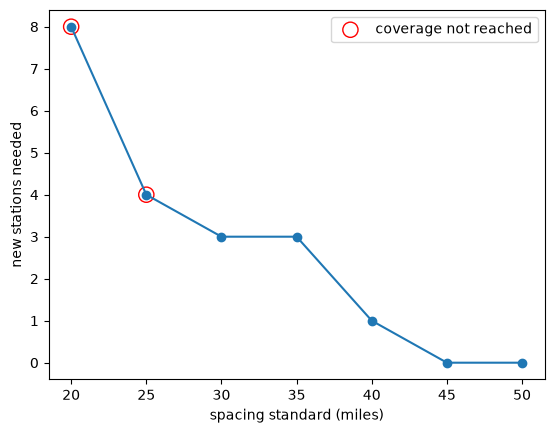

,miles,coverage_before,new_stations,coverage_after,where
0,50,1.000000,0,1.000000,[]
1,45,1.000000,0,1.000000,[]
2,40,0.972682,1,1.000000,[Paul Smiths]
3,35,0.972636,3,1.000000,"[Gouverneur, Paul Smiths, Canton]"
4,30,0.972621,3,1.000000,"[Gouverneur, Canton, Hogansburg]"
5,25,0.625013,4,0.961816,"[Cooperstown, Canton, Hogansburg, Pulaski]"
6,20,0.606510,8,0.956337,"[Cherry Valley, Cattaraugus, Spencer, Cooperstown, Sherburne, Mount Morris, Canton, Monticello]"


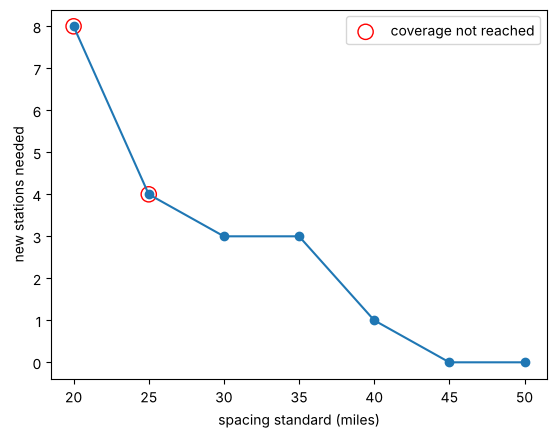

,miles,coverage_before,new_stations,coverage_after,where
0,50,1.000000,0,1.000000,[]
1,45,1.000000,0,1.000000,[]
2,40,0.972682,1,1.000000,[Paul Smiths]
3,35,0.972636,3,1.000000,"[Gouverneur, Paul Smiths, Canton]"
4,30,0.972621,3,1.000000,"[Gouverneur, Canton, Hogansburg]"
5,25,0.625013,4,0.961816,"[Cooperstown, Canton, Hogansburg, Pulaski]"
6,20,0.606510,8,0.956337,"[Cherry Valley, Cattaraugus, Spencer, Cooperstown, Sherburne, Mount Morris, Canton, Monticello]"


In [76]:
rows = []
for eps in [50, 45, 40, 35, 30, 25, 20]:
    chosen, curve = add_stations(eps, 40)
    rows.append([eps, curve[0], len(chosen), curve[-1], [cand["city"][c] for c in chosen]])
    print(eps, "miles:", len(chosen), "new stations")

cost = pd.DataFrame(rows, columns=["miles", "coverage_before", "new_stations", "coverage_after", "where"])

plt.figure()
plt.plot(cost["miles"], cost["new_stations"], marker="o")
not_done = cost[cost["coverage_after"] < 1]
plt.scatter(not_done["miles"], not_done["new_stations"], s=120, facecolors="none", edgecolors="red", label="coverage not reached")
plt.xlabel("spacing standard (miles)")
plt.ylabel("new stations needed")
plt.legend()
plt.savefig("cost_curve.png")
plt.show()

cost

### 11.4 What the cost curve shows

- At **45 and 50 miles** no new stations are needed: the current network already connects every pair of cities. The 50-mile benchmark from the former federal guidance is already met.
- From **30 to 40 miles**, 1 to 3 new stations are enough, all in the **North Country** (Gouverneur, Canton, Hogansburg, Paul Smiths).
- At **25 and 20 miles** coverage stops at about 0.96 (red circles). The gap between central New York and the North Country (Watertown, Fort Drum, Massena, Ogdensburg) is longer than the standard, and no existing Level 1 or Level 2 location lies along it. Meeting these standards would need new host sites, not only upgrades of existing ones.
- So the cost of a stricter standard is not spread across the state: it is concentrated in one region.

## 12. Control: is the network well sited?

Some of the weakness could come from the shape of New York itself, not from where chargers were placed. To separate the two, we compare the real network with **random networks built from the same pool of locations** (proposal, Step 4).

**How each random network is built:**
1. The pool is every public charging location in New York: the 754 fast-charging sites plus the 4756 Level 1 / Level 2 locations from section 11 (5510 locations in total).
2. We draw 754 locations from the pool at random, without replacement, so the random network has the same size as the real one.
3. We build the epsilon-neighborhood graph and compute the same measures as for the real network.

We repeat this 100 times (`rng` seed 42). Road distances only exist for the real sites, so here **both** the real and the random networks use straight-line × 1.2, to keep the comparison fair.

**Measures:**
- `mst_threshold`: longest MST link, the smallest standard at which the network is one piece (section 4.2)
- `coverage_30`, `coverage_40`: coverage at 30 and 40 miles (section 9)
- `weighted_coverage_30`: population-weighted coverage at 30 miles
- `cut_points_30`: number of single points of failure at 30 miles (section 5)

In [79]:
def network_stats(lat, lon):
    dist = miles(lat, lon, lat, lon)
    Cs = miles(places["lat"].values, places["lon"].values, lat, lon)
    n = len(dist)
    i, j = np.triu_indices(n, 1)
    full = ig.Graph(n=n, edges=list(zip(i, j)))
    full.es["weight"] = dist[i, j]
    mst = full.spanning_tree(weights=full.es["weight"])
    threshold = max(mst.es["weight"])
    u30, w30 = coverage(build_graph(dist, 30), Cs, 30, pop)
    u40, w40 = coverage(build_graph(dist, 40), Cs, 40, pop)
    cut30 = len(build_graph(dist, 30).articulation_points())
    return [threshold, u30, u40, w30, cut30]

pool_lat = np.append(sites["Latitude"].values, cand["lat"].values)
pool_lon = np.append(sites["Longitude"].values, cand["lon"].values)
print("pool:", len(pool_lat))

real = network_stats(sites["Latitude"].values, sites["Longitude"].values)

rng = np.random.default_rng(42)
rows = []
for t in range(100):
    pick = rng.choice(len(pool_lat), size=len(sites), replace=False)
    rows.append(network_stats(pool_lat[pick], pool_lon[pick]))

cols = ["mst_threshold", "coverage_30", "coverage_40", "weighted_coverage_30", "cut_points_30"]
rand = pd.DataFrame(rows, columns=cols)

pool: 5510


### 12.1 Real vs random

`share_random_better` is the share of the 100 random networks that do **better** than the real one (lower threshold, higher coverage, or fewer single points of failure). A small value means the real network is better than chance.

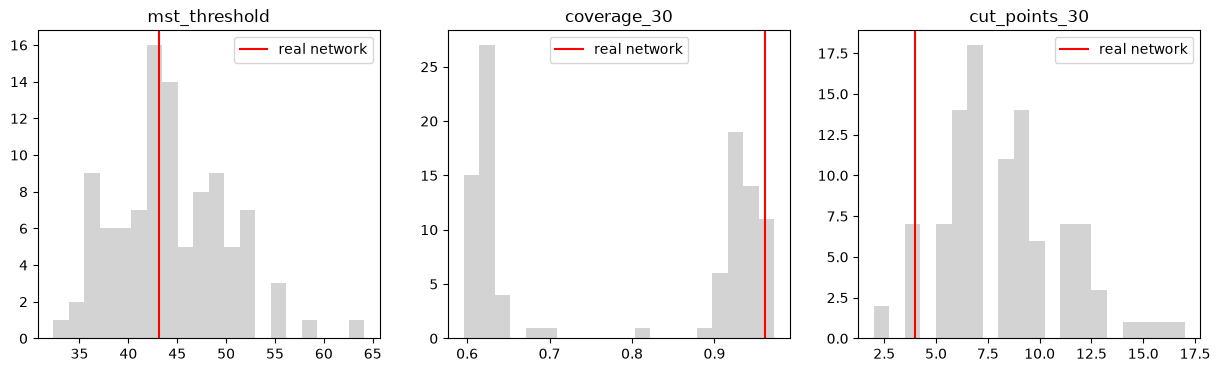

,real,random_mean,random_5%,random_95%,share_random_better
mst_threshold,43.115156,44.356726,35.960350,53.036595,0.43
coverage_30,0.961754,0.782921,0.601120,0.956362,0.02
coverage_40,0.972682,0.974780,0.956411,1.000000,0.46
weighted_coverage_30,0.984077,0.822195,0.654589,0.980358,0.02
cut_points_30,4.000000,8.130000,4.000000,13.000000,0.02


In [81]:
better = [
    (rand["mst_threshold"] < real[0]).mean(),
    (rand["coverage_30"] > real[1]).mean(),
    (rand["coverage_40"] > real[2]).mean(),
    (rand["weighted_coverage_30"] > real[3]).mean(),
    (rand["cut_points_30"] < real[4]).mean(),
]
summary = pd.DataFrame({
    "real": real,
    "random_mean": rand.mean(),
    "random_5%": rand.quantile(0.05),
    "random_95%": rand.quantile(0.95),
    "share_random_better": better,
}, index=cols)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, k in [(axes[0], "mst_threshold", 0), (axes[1], "coverage_30", 1), (axes[2], "cut_points_30", 4)]:
    ax.hist(rand[col], bins=20, color="lightgray")
    ax.axvline(real[k], c="red", label="real network")
    ax.set_title(col)
    ax.legend()
plt.savefig("control.png")
plt.show()

summary

### 12.2 What the control shows

- **At a 30-mile standard the real network is better than chance.** Only 2% of random networks reach its coverage (0.96, or 0.98 weighted), and only 2% have as few single points of failure (4, against 8 on average).
- The coverage of random networks at 30 miles falls into **two groups**: around 0.6, where the state splits into two large pieces, and around 0.93. The real network avoids the split and does better than even the second group. The siting of fast chargers along the main corridors (for example the Thruway) is better than a random choice from the same locations.
- **The overall threshold is not better than chance.** The longest MST link of the real network (43.1 miles) is close to the random average (44.4), and coverage at 40 miles is the same (0.973 vs 0.975). Random networks do not close the North Country gap either.
- So the remaining weak point is a matter of **geography**: the existing charging locations, real or random, are where people and businesses are, and the North Country has few of them. This agrees with section 11: closing that gap needs new host sites, not only upgrades of existing ones.

## 13. Summary of findings

All numbers use road distances and the full network (754 sites), unless stated.

**Q1: When does the network split?**
- The 1.2 factor is a little low for New York: the median road / straight-line ratio is 1.27.
- Below about 24 miles the network is in many pieces. Between 24 and 30 miles the pieces join and connectivity jumps from 0.56 to 0.99.
- The whole state is one piece only from **43.5 miles** (the longest MST link). The straight-line × 1.2 estimate gives almost the same value (43.1).

**Q2: Which stations hold it together?**
- At 30 miles there are 5 single points of failure. Four of them are Tesla Superchargers in rural areas (Chestertown, Peru, Monticello, Roscoe). Chestertown alone cuts off 24 sites.
- Critical sites are **small**: their median degree is 9, compared with 50 for all sites. Degree does not show importance in this network.
- Under **random failure** the network stays close to the best possible curve (R about 0.70 at 50 miles).
- An **attack by degree** removes busy New York City and Long Island sites and does about as much damage as random failure.
- An **attack by betweenness** removes the rural corridor sites first (Schoharie, Arkville, Roscoe, Herkimer, Little Falls, ...). Removing 15 sites (2% of the network) drops connectivity at 50 miles from 1.00 to 0.57.

**Coverage is not connectivity**
- Connectivity counts sites, so it is dominated by New York City and Long Island. Coverage counts pairs of cities (362 places with at least 5000 people), with and without population weights.
- At 30 and 40 miles connectivity is 0.99, but coverage is 0.97: some small cities have no charger close enough, even though almost all sites are connected.
- Random failure and attack by degree barely change coverage (R about 0.99 at 50 miles).
- Attack by betweenness cuts coverage to 0.47 (unweighted) and 0.56 (weighted) on average at 50 miles. What breaks is the link **between regions**, not service inside a region.

**Q3: How many new stations would each standard need?**
- Candidate sites are the 4756 public Level 1 / Level 2 locations.
- At **45 and 50 miles** no new stations are needed: every pair of cities is already connected.
- From **30 to 40 miles** 1 to 3 new stations are enough, all in the North Country (Gouverneur, Canton, Hogansburg, Paul Smiths).
- At **25 and 20 miles** coverage stops at about 0.96. No existing location lies along the gap to the North Country (Watertown, Fort Drum, Massena, Ogdensburg), so these standards need new host sites.

**Control: is the network well sited?**
- Compared with 100 random networks of 754 locations drawn from all 5510 public charging locations, the real network is better than 98% of them at 30 miles (coverage 0.96 vs 0.78 on average; 4 single points of failure vs 8).
- Its overall threshold (43 miles) and its coverage at 40 miles are about average. Random networks do not close the North Country gap either, so that gap comes from geography, not from siting decisions.

**Conclusion:** the network already meets a 50-mile standard and is well sited along the main corridors. Its weak points are a small number of low-degree rural chargers that link the regions, and one geographic gap to the North Country. Protecting the corridor chargers and adding a few stations in the North Country would do more for statewide travel than adding chargers where they are already dense.